# Homework 3

46-921, Financial Data Science I

Due September 17, 2026 at 11:59 PM

In [1]:
import numpy as np
import pandas as pd

This exercise is based on the "Benchmark Bond Trade Price Challenge" which
was conducted on the web site Kaggle.com.
You can see the full details of this challenge at
[http://www.kaggle.com/c/benchmark-bond-trade-price-challenge](http://www.kaggle.com/c/benchmark-bond-trade-price-challenge),
but you may have to register (it is free).
This is reproduced from the "Background" section:

<blockquote>
As far as price transparency is concerned, there has historically been a huge gap between the amount of reference information available to those trading equities versus those trading corporate bonds.  Stock exchanges report trades, bids and offers at all times.  Free access is available online with a 15 minute delay while traders who demand more information can pay for ultra efficient real time data and information about size of current bids and offers. By contrast, bond trades are required to be reported within 15 minutes and only those who pay for the TRACE feed can access this information.  No quotes are publicly available and the best way to get a quote is to solicit multiple brokers and wait for a reply.  Alternatively there are data companies that provide end of day prices, published after the market has closed and with no guarantee that the specific information sought will be included.  Accurate bond pricing is also hindered by lack of liquidity.  Only a fraction of TRACE eligible bonds trade on a given day, so the most recent trade price is often multiple days old.  Pricing bonds based on other more liquid bonds that have similar features is common, but again limited by the presence of such bonds.

Benchmark Solutions is the first provider of realtime corporate bond prices. Every 10 seconds we provide accurate prices that incorporate interest rate data, trades or quotes of the bond in question, trades or quotes of other bonds or CDS of the issuer of the bond in question as well as other input sources.  Pricing bonds accurately requires an exacting knowledge of payment schedules, trading calenders and reference data for each bond.  This, as well as synthesizing all of the bonds and CDS quotes and trades of a given issuer into implied hazard and funding curves, is something that we feel is beyond the scope of this challenge.  Rather, we provide you with a reference price which is an intermediate result of our calculations and is labeled 'curve\_based\_price'  in the dataset. Thus the competition focuses on trading dynamics and microstructure of individual bonds, rather than all bonds from a given issuer.
</blockquote>

We created a reduced data set in order to make this challenge
something we could manage during this exercise. This data set is availble at
[http://www.stat.cmu.edu/~cschafer/MSCF/bonddata.txt](http://www.stat.cmu.edu/~cschafer/MSCF/bonddata.txt).

We will fit regression models with `trade_price` as the response variable.

## Setup

This initial portion of code reads in the data set.

In [2]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

In [3]:
data = pd.read_csv("http://www.stat.cmu.edu/~cschafer/MSCF/bonddata.txt")

These are the first few rows of the data set.

In [4]:
data.head()

,id,bond_id,trade_price,weight,current_coupon,time_to_maturity,is_callable,reporting_delay,trade_size,trade_type,...,received_time_diff_last9,trade_price_last9,trade_size_last9,trade_type_last9,curve_based_price_last9,received_time_diff_last10,trade_price_last10,trade_size_last10,trade_type_last10,curve_based_price_last10
0,10,1,126.268,7.616851,5.950,25.940349,0,12.540,150000.0,3,...,2862729,128.596,120000.0,2,127.561201,3621492,129.089,200000.0,2,129.435587
1,38,2,101.009,0.018373,3.550,0.326392,0,9.327,450000.0,3,...,532644,101.086,500000.0,2,101.103180,538510,101.070,25000.0,2,101.102243
2,336,3,108.144,3.537380,4.200,2.340601,0,0.102,160000.0,4,...,96293,107.917,400000.0,2,107.874965,96293,107.917,400000.0,4,107.874965
3,781,4,116.953,0.402523,4.875,7.367653,0,52.093,10000.0,4,...,92559,115.924,10000.0,2,116.160420,97177,116.458,2000.0,3,116.342802
4,1172,14,133.210,0.210685,10.750,4.159301,0,13.722,25000.0,4,...,6400208,127.500,25000.0,2,131.066998,6400208,127.500,25000.0,4,131.066998


The size of the data set.

In [5]:
data.shape

(1620, 61)

These next commands remove some variables which are not useful predictors, and defines some variables to be categorical.

In [6]:
data = data.drop(['id', 'bond_id'], axis=1)

In [7]:
cols = ['is_callable', 'trade_type'] + [f'trade_type_last{i}' for i in range(1, 11)]
data[cols] = data[cols].apply(lambda col: col.astype('category').cat.as_unordered())

## Transforming Predictors

Some of the non-categorical predictors have distributions which are highly skewed. For example, take a look at the  histogram below.

<Axes: >

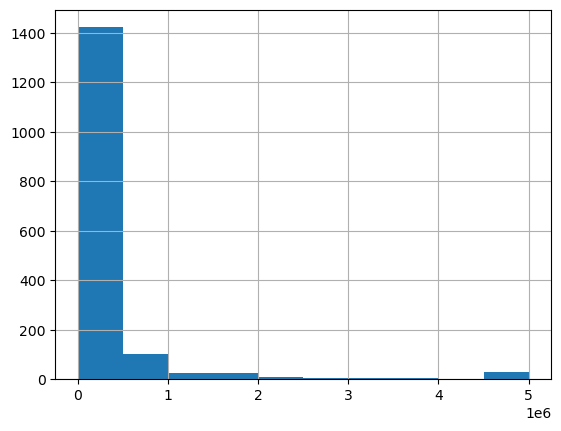

In [8]:
data['trade_size_last1'].hist()

For predictors with such a distribution, it can be a very good idea to transform them prior to fitting the model. For strictly positive variables, a log transform is common, while for nonnegative variables a square root transform has a similar effect. For this reason, the following transformations are applied.

In [9]:
log_cols = ['time_to_maturity', 'trade_size'] + [f'trade_size_last{i}' for i in range(1, 11)]
for col in log_cols:
    data[f'{col}_lt'] = np.log(data[col])

sqrt_cols = [f'received_time_diff_last{i}' for i in range(1, 11)]
for col in sqrt_cols:
    data[f'{col}_st'] = np.sqrt(data[col])

In [10]:
cols_to_drop = (
    [f'received_time_diff_last{i}' for i in range(1, 11)] +
    [f'trade_size_last{i}' for i in range(1, 11)] +
    ['time_to_maturity', 'trade_size']
)
datatransformed = data.drop(cols_to_drop, axis=1)

In [11]:
datatransformed.head()

,trade_price,weight,current_coupon,is_callable,reporting_delay,trade_type,curve_based_price,trade_price_last1,trade_type_last1,curve_based_price_last1,...,received_time_diff_last1_st,received_time_diff_last2_st,received_time_diff_last3_st,received_time_diff_last4_st,received_time_diff_last5_st,received_time_diff_last6_st,received_time_diff_last7_st,received_time_diff_last8_st,received_time_diff_last9_st,received_time_diff_last10_st
0,126.268,7.616851,5.950,0,12.540,3,126.017363,125.101,3,124.717608,...,586.299412,587.409568,827.276254,1138.199455,1143.881113,1467.292745,1468.805637,1551.676835,1691.960106,1903.021808
1,101.009,0.018373,3.550,0,9.327,3,101.068546,101.009,2,101.068546,...,1.000000,60.778286,89.543286,95.749674,135.440024,590.292300,669.789519,723.537145,729.824636,733.832406
2,108.144,3.537380,4.200,0,0.102,4,107.927659,107.990,2,107.922875,...,272.284777,273.237992,289.815459,289.891359,291.082463,291.082463,292.518375,303.326557,310.311134,310.311134
3,116.953,0.402523,4.875,0,52.093,4,116.552464,115.842,2,116.542486,...,30.967725,32.969683,114.860785,294.277080,294.348433,302.160553,302.162208,302.162208,304.235106,311.732257
4,133.210,0.210685,10.750,0,13.722,4,130.202417,133.612,4,130.211787,...,16.186414,829.783104,1692.365504,1993.787852,1993.787852,2351.207137,2354.411816,2355.126536,2529.863237,2529.863237


## Constructing the Design Matrix

This next command will appropriate construct the design matrix for this model. The first version `designmatrix` does not contain the column of ones, while the second version `desginmatrix_withones` does include that column of ones.

In [12]:
designmatrix = pd.get_dummies(datatransformed,drop_first=True)

In [13]:
import statsmodels.api as sm

designmatrix_withones = sm.add_constant(designmatrix)

## Exercises

Now, do each of the following:

1. Fit the model using including all of the predictors (i.e., using the entire design matrix you just constructed), via `sm.OLS`. Remember that `trade_price` is the response. Show the `summary` output.

2. Construct the plot of residuals versus fitted values for the model fit in Question 1. Comment on the quality of the fit.

3. Construct the normal probability plot of the residuals. What does this plot tell us?

4. Implement a stepwise variable selection procedure using AIC to find a simpler model. Report on the resulting model.

5. Repeat the above, but use leave-one-out cross-validation instead of AIC. How does the resulting model change? 